# <h1><center>Introduction to Machine Learning and Data Science</center></h1>
# <h1><center>Assignment 4</center></h1>
### <h1><center>Important NOTE: In order to get full credit, for every question, you need to provide the details of your work on how to get to a solution or the end of the proof.</center></h1>
### <h1><center>Instructor: Tan Bui-Thanh</center></h1>
### <h1><center>TA: Cevahir Koprulu</center></h1>
#### <h1><center>Due: 11pm 10/30/2026</center></h1>
### Submit a single pdf. All code outputs should be reported in the pdf.

Download the latest version of the lecture notes before starting. Question and exercise numbering refers to that version.

A subset of these questions will be graded. The subset is not announced in advance, so answer all twelve.

In this class, unless otherwise stated, all vectors are column vectors, and they are written in boldface fonts.

In [11]:
# --- COE 379L standard preamble ---------------------------------
# Pin versions so this notebook still runs next semester.
!pip install -q "jax[cpu]==0.4.35" "optax==0.2.3" "ucimlrepo"

import jax, jax.numpy as jnp, numpy as np, platform
import matplotlib.pyplot as plt

# Double precision. Read Section C.3 before removing this line.
jax.config.update("jax_enable_x64", True)

print("python  :", platform.python_version())
print("jax     :", jax.__version__)
print("devices :", jax.devices())
print("x64 on  :", jnp.zeros(1).dtype == jnp.float64)

/usr/lib/python3.13/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


python  : 3.13.5
jax     : 0.4.35
devices : [CpuDevice(id=0)]
x64 on  : True


---

## Question 1

*Notes, Chapter 9, Exercise 9.*

Reproduce Example 9.1.1. Fit both a softmax classifier and a two class GDA to the same well separated blobs, then evaluate each at a point far outside the data. Report the posterior from both and the marginal $\mathbb{P}(\mathbf{x})$ from the GDA, and confirm the posteriors agree while only one model registers anything unusual. Then set a density threshold that rejects 1% of the training data and report how far from the means a point must lie to be rejected.

In [12]:
# Question 1: your code here

key = jax.random.PRNGKey(0)

# Get training data from a GMM with means (0,0) and (4,0) and cov 0.6I
true_means = jnp.array([[0.0,0.0], [4.0,0.0]])
true_covmat = 0.6*jnp.eye(2)

@jax.jit
def sample(key):
    key_bern, key_norm = jax.random.split(key)
    y = jax.random.bernoulli(key_bern, 0.5).astype(jnp.int32)
    x = true_means[y] + true_covmat @ jax.random.normal(key_norm, shape=(2,))/jnp.sqrt(0.6)
    return x,y

n_data = 1000
def generate_data(key, n):
    keys = jax.random.split(key, n)
    X, Y = jax.vmap(sample)(keys)
    return X, Y

X_data, y_data = generate_data(key, n_data)

# Two-class GDA
MLE_weights = jnp.array([jnp.mean(y_data == k) for k in (0,1)])
MLE_means = jnp.array([X_data[y_data == k].mean(axis=0) for k in (0,1)])
resids = X_data - MLE_means[y_data]
MLE_cov = (resids.T @ resids) / n_data

def log_gauss(x, m):
    diff = np.atleast_2d(x) - m
    return -0.5 * np.einsum("ij,jk,ik->i", diff, jnp.linalg.inv(MLE_cov), diff) - 0.5 * (X_data.shape[1] * np.log(2 * np.pi) + jnp.linalg.slogdet(MLE_cov)[1])

def gda_log_joint(x):
    return np.stack([np.log(MLE_weights[k]) + log_gauss(x, MLE_means[k]) for k in (0, 1)], axis=1)

def gda_posterior(x):
    logjoint = gda_log_joint(x)
    return np.exp(logjoint[:, 1] - np.logaddexp(logjoint[:, 0], logjoint[:, 1]))

def gda_marginal(x):
    logjoint = gda_log_joint(x)
    return np.exp(np.logaddexp(logjoint[:, 0], logjoint[:, 1]))

# Softmax Classifier 
Phi = jnp.hstack([jnp.ones((n_data, 1)), jnp.asarray(X_data)])
Y = jax.nn.one_hot(jnp.asarray(y_data), 2)
lam = 1e-3

def loss(W):                      
    logits = Phi @ W
    return -jnp.mean(jnp.sum(Y * jax.nn.log_softmax(logits), axis=1)) + 0.5 * lam * jnp.sum(W[1:] ** 2)

grad = jax.jit(jax.grad(loss))
W = jnp.zeros((3, 2))
for _ in range(5000):
    W = W - 0.5 * grad(W)

def softmax_posterior(x):
    x = np.atleast_2d(x)
    logits = np.hstack([np.ones((len(x), 1)), x]) @ np.asarray(W)
    return np.asarray(jax.nn.softmax(logits, axis=1))[:, 1]

# Evaluation
queries = np.array([[3.6, 0.2], [2.0, 0.0], [4.2, 9.0], [25.0, 0.0]])
print(f"{'x':>12} | {'softmax P(y=2|x)':>16} | {'GDA P(y=2|x)':>13} | {'GDA P(x)':>10}")
for q in queries:
    print(f"{f'({q[0]:g}, {q[1]:g})':>12} | {softmax_posterior(q)[0]:16.3f} | {gda_posterior(q)[0]:13.3f} | {gda_marginal(q)[0]:10.2e}")
print("density at a class centre:", gda_marginal(MLE_means[1])[0])

# Density Threshold Rejection
p_train = gda_marginal(X_data)                       # P(x) at every training point
tau = np.quantile(p_train, 0.01)                     # 1st percentile -> 1% fall below it
print(f"\nthreshold tau = {tau:.3e}  (rejects {np.mean(p_train < tau):.1%} of training points)")

# How far from a mean must a point be to be rejected?
r = np.linspace(0, 6, 60001)
directions = {"+x1 (away from other class)": [1, 0], "+x2 (perpendicular)": [0, 1],
              "-x2 (perpendicular)": [0, -1], "diagonal": [1/np.sqrt(2), 1/np.sqrt(2)]}
for k in (0, 1):
    for name, u in directions.items():
        u = np.array(u, float)
        if k == 0: u[0] = -u[0]                      # for class 1, "away" is the -x1 direction
        pts = np.asarray(MLE_means[k]) + r[:, None] * u
        r_rej = r[np.argmax(gda_marginal(pts) < tau)]
        print(f"class {k+1}, along {name:>28}: rejected beyond distance {r_rej:.3f}")

           x | softmax P(y=2|x) |  GDA P(y=2|x) |   GDA P(x)
  (3.6, 0.2) |            0.999 |         1.000 |   1.20e-01
      (2, 0) |            0.481 |         0.588 |   8.98e-03
    (4.2, 9) |            1.000 |         1.000 |   4.90e-31
     (25, 0) |            1.000 |         1.000 |  2.97e-165
density at a class centre: 0.1382399003738432

threshold tau = 1.998e-03  (rejects 1.0% of training points)
class 1, along  +x1 (away from other class): rejected beyond distance 2.216
class 1, along          +x2 (perpendicular): rejected beyond distance 2.233
class 1, along          -x2 (perpendicular): rejected beyond distance 2.233
class 1, along                     diagonal: rejected beyond distance 2.218
class 2, along  +x1 (away from other class): rejected beyond distance 2.231
class 2, along          +x2 (perpendicular): rejected beyond distance 2.248
class 2, along          -x2 (perpendicular): rejected beyond distance 2.248
class 2, along                     diagonal: rejected b

---

## Question 2

*Notes, Chapter 9, Exercise 10.*

Reproduce the conditioning table of Example 9.4.1. Draw $n_k$ samples from $\mathcal{N}(\mathbf{0}, \mathrm{I})$ in $d = 10$, form the sample covariance, and record its condition number, repeating enough times for a stable median. Confirm the singular case at $n_k \le d$ and the decay thereafter. How large must $n_k/d$ be before $\kappa < 2$?

In [13]:
# Question 2: your code here

key = jax.random.PRNGKey(0)
d = 10 # dimension

# Sample from Gaussian
sample = lambda key: jax.random.normal(key, shape=(d,))

def get_condition_number(key, n):
    keys = jax.random.split(key, n)
    samples = jax.vmap(sample)(keys)
    cov = jnp.cov(samples.T)
    kappa = jnp.linalg.cond(cov)

    return kappa

def batch_kappa(key, n, reps=2000):
    key_reps = jax.random.split(key, reps)
    kappa_ests = jax.vmap(get_condition_number, in_axes=(0,None))(key_reps, n)
    return kappa_ests

for i, nk in enumerate([5, 10, 11, 15, 100, 200, 225, 238, 239, 240, 250, 500, 1000]):
    kappas = batch_kappa(jax.random.fold_in(key, i), nk)
    print(f"Median Condition Number for {nk} samples: {jnp.median(kappas)}")

Median Condition Number for 5 samples: 3.802010076264629e+17
Median Condition Number for 10 samples: 4.977435190365003e+16
Median Condition Number for 11 samples: 975.6089736975646
Median Condition Number for 15 samples: 51.03899881885505
Median Condition Number for 100 samples: 2.9992441582740685
Median Condition Number for 200 samples: 2.142445982548468
Median Condition Number for 225 samples: 2.0518292253540986
Median Condition Number for 238 samples: 2.006042841738469
Median Condition Number for 239 samples: 2.006841468697532
Median Condition Number for 240 samples: 2.002765952970353
Median Condition Number for 250 samples: 1.9791208309084327
Median Condition Number for 500 samples: 1.613563292146074
Median Condition Number for 1000 samples: 1.3973825645668088


---

## Question 3

*Notes, Chapter 9, Exercise 13.*

Show that if all classes share a covariance, $\Sigma_k = \Sigma$, the quadratic terms cancel and the boundary $\mathbb{P}(y = j \mid \mathbf{x}) = \mathbb{P}(y = k \mid \mathbf{x})$ is a hyperplane, as in Figure 9.3a. Show further that the induced $\mathbb{P}(y \mid \mathbf{x})$ has exactly the logistic form of Chapter 8.

---

## Question 4

*Notes, Chapter 10, Exercise 22.*

Reproduce Figure 10.1. Using (10.9), confirm $\kappa(\mathbf{H}) \approx 6.8$. From $\boldsymbol{\theta}^0 = (-1.6, 2.2)$ run 80 steps of full batch gradient descent and 80 of Algorithm 6 at $|\mathcal{B}| = 1$, both at $\alpha$, and plot the two paths over level sets of $J$. Report $\|\boldsymbol{\theta}^{80} - \boldsymbol{\theta}^\star\|$ for each (roughly 0.15 and 0.6) and count the sample evaluations each consumed. Then answer: is the stochastic path's failure to settle a property of the step size, of the batch size, or of both?

eigenvalues of H = [0.14951645 1.01937169],  kappa(H) = 6.82
L = 1.0194,  alpha = 1/(4L) = 0.2452,  theta* = [ 0.98486271 -0.82151894]
GD : ||theta^80 - theta*|| = 0.149,  sample evaluations = 32000
SGD: ||theta^80 - theta*|| = 0.278,  sample evaluations = 80
SGD over 2000 runs: median distance 0.363, RMS 0.431


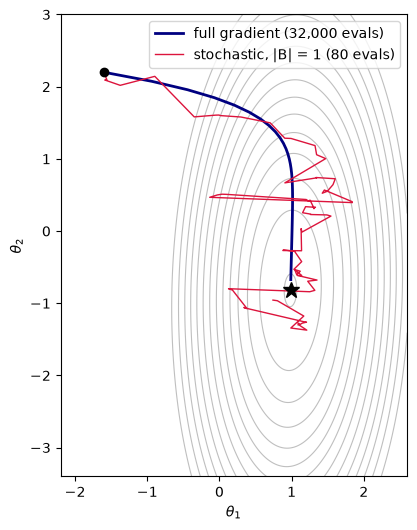

<Figure size 640x480 with 0 Axes>

In [14]:
# Question 4: your code here
from functools import partial

# ---- Data: problem (10.9) ----
key_data = jax.random.PRNGKey(4)    
n_data = 400
A = jnp.diag(jnp.array([1.0, 0.38]))
theta_gen = jnp.array([1.0, -0.8])
noise = 0.7

def sample(key):
    key_z, key_eps = jax.random.split(key)
    x = A @ jax.random.normal(key_z, shape=(2,))
    y = x @ theta_gen + noise * jax.random.normal(key_eps)
    return x, y

def generate_data(key, n):
    keys = jax.random.split(key, n)
    X, Y = jax.vmap(sample)(keys)
    return X, Y

X_data, y_data = generate_data(key_data, n_data)
H = X_data.T @ X_data / n_data                                        
theta_star = jnp.linalg.solve(X_data.T @ X_data, X_data.T @ y_data)   
alpha = 1.0 / (4 * jnp.linalg.eigvalsh(H)[-1])                        
eigs = jnp.linalg.eigvalsh(H)
print(f"eigenvalues of H = {eigs},  kappa(H) = {eigs[-1] / eigs[0]:.2f}")
print(f"L = {eigs[-1]:.4f},  alpha = 1/(4L) = {alpha:.4f},  theta* = {theta_star}")

# L2 loss and gradients
def loss_i(theta, x, y):                     
    return 0.5 * (x @ theta - y) ** 2
grad_i = jax.grad(loss_i)                    

def batch_grad(theta, key, B):
    idx = jax.random.randint(key, (B,), 0, n_data)
    return jnp.mean(jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data[idx], y_data[idx]), axis=0)

def J(theta):
    return 0.5 * jnp.mean((X_data @ theta - y_data) ** 2)
full_grad = jax.grad(J)                       

# Full-batch GD vs. SGD (|B| = 1)
key = jax.random.PRNGKey(0)                   
T = 80
theta0 = jnp.array([-1.6, 2.2])

@jax.jit
def run_gd(theta0):
    def step(theta, _):
        theta = theta - alpha * full_grad(theta)
        return theta, theta
    _, path = jax.lax.scan(step, theta0, None, length=T)
    return jnp.vstack([theta0, path])

@partial(jax.jit, static_argnames="B")
def run_sgd(key, theta0, B):
    def step(theta, k):
        theta = theta - alpha * batch_grad(theta, k, B)
        return theta, theta
    _, path = jax.lax.scan(step, theta0, jax.random.split(key, T))
    return jnp.vstack([theta0, path])

gd_path = run_gd(theta0)
sgd_path = run_sgd(jax.random.fold_in(key, 1), theta0, B=1)
print(f"GD : ||theta^80 - theta*|| = {jnp.linalg.norm(gd_path[-1] - theta_star):.3f},  sample evaluations = {T * n_data}")
print(f"SGD: ||theta^80 - theta*|| = {jnp.linalg.norm(sgd_path[-1] - theta_star):.3f},  sample evaluations = {T * 1}")

# SGD's distance is random: also report it over many independent runs
runs = 2000
ends = jax.vmap(lambda k: run_sgd(k, theta0, B=1)[-1])(jax.random.split(jax.random.fold_in(key, 2), runs))
dist = jnp.linalg.norm(ends - theta_star, axis=1)
print(f"SGD over {runs} runs: median distance {jnp.median(dist):.3f}, RMS {jnp.sqrt(jnp.mean(dist ** 2)):.3f}")

# Paths over the level sets of J
g1, g2 = jnp.meshgrid(jnp.linspace(-2.2, 2.6, 300), jnp.linspace(-3.4, 3.0, 300))
Jgrid = jax.vmap(jax.vmap(lambda a, b: J(jnp.array([a, b]))))(g1, g2)
plt.figure(figsize=(6, 6))
plt.contour(g1, g2, Jgrid, levels=jnp.quantile(Jgrid.ravel(), jnp.linspace(0.002, 0.6, 14)), colors="0.75", linewidths=0.8)
plt.plot(*gd_path.T, c="navy", lw=2, label="full gradient (32,000 evals)")
plt.plot(*sgd_path.T, c="crimson", lw=1, label="stochastic, |B| = 1 (80 evals)")
plt.plot(*theta_star, "k*", ms=12); plt.plot(*theta0, "ko")
plt.xlabel(r"$\theta_1$"); plt.ylabel(r"$\theta_2$"); plt.legend(); plt.gca().set_aspect("equal")
plt.show()
plt.savefig("HW4Problem4.jpg")

---

## Question 5

*Notes, Chapter 10, Exercise 23.*

Reproduce Figure 10.2. Fix the probe point $\boldsymbol{\theta} = \boldsymbol{\theta}^\star + (0.35, -0.25)$. For $|\mathcal{B}| = 1, 2, 4, \dots, 256$ estimate $\mathbb{E}\|\mathbf{g}_{\mathcal{B}} - \nabla_{\boldsymbol{\theta}} J\|^2$ by resampling the batch at least 4000 times, and plot it against $|\mathcal{B}|$ on log–log axes. Fit the slope; you should get $-1.00$ to two figures. Overlay $\sigma^2/|\mathcal{B}|$ anchored at $|\mathcal{B}| = 1$ and confirm the measured points lie on it. How few resamplings can you use before the fitted slope becomes unreliable?

sigma^2(theta) = 0.9402
fitted slope with R = 4000: -1.005
|B| =   1: measured 9.1648e-01   sigma^2/|B| = 9.4022e-01   ratio 0.975
|B| =   2: measured 4.9295e-01   sigma^2/|B| = 4.7011e-01   ratio 1.049
|B| =   4: measured 2.4589e-01   sigma^2/|B| = 2.3505e-01   ratio 1.046
|B| =   8: measured 1.1831e-01   sigma^2/|B| = 1.1753e-01   ratio 1.007
|B| =  16: measured 5.8298e-02   sigma^2/|B| = 5.8764e-02   ratio 0.992
|B| =  32: measured 2.9552e-02   sigma^2/|B| = 2.9382e-02   ratio 1.006
|B| =  64: measured 1.4672e-02   sigma^2/|B| = 1.4691e-02   ratio 0.999
|B| = 128: measured 7.3817e-03   sigma^2/|B| = 7.3454e-03   ratio 1.005
|B| = 256: measured 3.5991e-03   sigma^2/|B| = 3.6727e-03   ratio 0.980


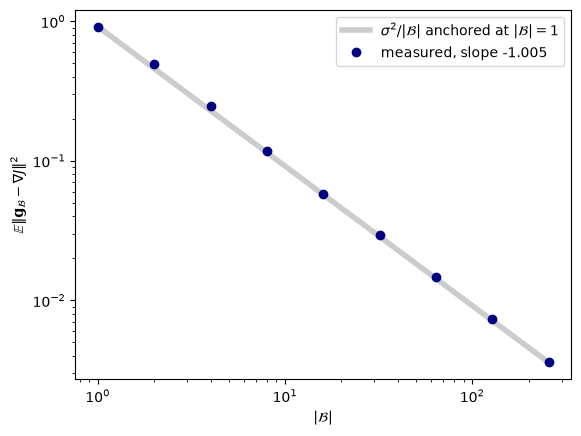


    R   mean slope   std of slope   95% interval
    5     -0.951        0.132     [-1.178, -0.703]
   10     -0.973        0.113     [-1.188, -0.770]
   20     -0.981        0.076     [-1.133, -0.836]
   50     -0.987        0.054     [-1.085, -0.892]
  100     -0.993        0.036     [-1.062, -0.929]
  200     -0.998        0.027     [-1.041, -0.945]
  500     -0.999        0.017     [-1.034, -0.966]
 1000     -0.998        0.011     [-1.024, -0.979]
 4000     -1.000        0.006     [-1.011, -0.990]


<Figure size 640x480 with 0 Axes>

In [15]:
# Question 5: your code here
from functools import partial

key_data = jax.random.PRNGKey(4)
n_data = 400
A = jnp.diag(jnp.array([1.0, 0.38]))
theta_gen = jnp.array([1.0, -0.8])
noise = 0.7

def sample(key):
    key_z, key_eps = jax.random.split(key)
    x = A @ jax.random.normal(key_z, shape=(2,))
    y = x @ theta_gen + noise * jax.random.normal(key_eps)
    return x, y

def generate_data(key, n):
    keys = jax.random.split(key, n)
    X, Y = jax.vmap(sample)(keys)
    return X, Y

X_data, y_data = generate_data(key_data, n_data)
H = X_data.T @ X_data / n_data  
theta_star = jnp.linalg.solve(X_data.T @ X_data, X_data.T @ y_data) 
alpha = 1.0 / (4 * jnp.linalg.eigvalsh(H)[-1])                        

# L2 loss and gradients
def loss_i(theta, x, y):                     
    return 0.5 * (x @ theta - y) ** 2
grad_i = jax.grad(loss_i)             

def batch_grad(theta, key, B):
    idx = jax.random.randint(key, (B,), 0, n_data)
    return jnp.mean(jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data[idx], y_data[idx]), axis=0)

def per_sample_grads(theta):                  # (n, 2): every grad l_i at theta
    return jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data, y_data)

def J(theta):
    return 0.5 * jnp.mean((X_data @ theta - y_data) ** 2)
full_grad = jax.grad(J)

# Variance of mini-batch gradient at a fixed probe point
key = jax.random.PRNGKey(0)                   
theta = theta_star + jnp.array([0.35, -0.25])
gJ = full_grad(theta)
G = per_sample_grads(theta)
s2 = jnp.mean(jnp.sum((G - gJ) ** 2, axis=1)) 
print(f"sigma^2(theta) = {s2:.4f}")

Bs = [2 ** p for p in range(9)]    

@partial(jax.jit, static_argnames=("B", "R"))
def msd(key, B, R):
    g = jax.vmap(lambda k: batch_grad(theta, k, B))(jax.random.split(key, R))
    return jnp.mean(jnp.sum((g - gJ) ** 2, axis=1))

def fit_slope(vals):
    return jnp.polyfit(jnp.log(jnp.array(Bs, float)), jnp.log(vals), 1)[0]

R = 4000
m = jnp.array([msd(jax.random.fold_in(key, i), B, R) for i, B in enumerate(Bs)])
print(f"fitted slope with R = {R}: {fit_slope(m):.3f}")
for B, v in zip(Bs, m):
    print(f"|B| = {B:>3}: measured {v:.4e}   sigma^2/|B| = {s2 / B:.4e}   ratio {v / (s2 / B):.3f}")

Bs_arr = jnp.array(Bs)
plt.loglog(Bs_arr, m[0] / Bs_arr, c="0.8", lw=4, label=r"$\sigma^2/|\mathcal{B}|$ anchored at $|\mathcal{B}|=1$")
plt.loglog(Bs_arr, m, "o", c="navy", label=f"measured, slope {fit_slope(m):.3f}")
plt.xlabel(r"$|\mathcal{B}|$"); plt.ylabel(r"$\mathbb{E}\|\mathbf{g}_\mathcal{B}-\nabla J\|^2$"); plt.legend()
plt.show()
plt.savefig("HW4Problem5.jpg")

# Find how few resamplings before the slope is unreliable
def one_fit(key, R):
    return fit_slope(jnp.array([msd(jax.random.fold_in(key, i), B, R) for i, B in enumerate(Bs)]))

print("\n    R   mean slope   std of slope   95% interval")
for j, R in enumerate([5, 10, 20, 50, 100, 200, 500, 1000, 4000]):
    keys = jax.random.split(jax.random.fold_in(key, 100 + j), 200)
    slopes = jax.lax.map(lambda k: one_fit(k, R), keys) 
    lo, hi = jnp.percentile(slopes, jnp.array([2.5, 97.5]))
    print(f"{R:>5}   {slopes.mean():8.3f}   {slopes.std():10.3f}     [{lo:.3f}, {hi:.3f}]")


---

## Question 6

*Notes, Chapter 10, Exercise 24.*

Reproduce Figure 10.3. Run Algorithm 6 at $|\mathcal{B}| = 1$ for 4000 iterations under three schedules (constant $\alpha$, constant $\alpha/4$, and $\alpha_j = \alpha/(1 + 0.008j)$), averaging $J(\boldsymbol{\theta}^j) - J(\boldsymbol{\theta}^\star)$ over at least 40 independent runs. Plot all three on log–log axes. Confirm the two constant schedules flatten onto floors near $4.6 \times 10^{-2}$ and $8.0 \times 10^{-3}$ while the decaying one keeps descending, reaching about $1.2 \times 10^{-3}$ at $j = 4000$. Proposition 10.5.1 suggests the floors should fall in proportion to $\alpha$, so the measured ratio ought to be 4; it is closer to 5.8. Account for the discrepancy.

*Hint:* two separate effects contribute, and you can separate them numerically. First, even for a quadratic with noise of fixed covariance the exact stationary floor is $\frac{\alpha}{2}\sum_k s_k^2/(2 - \alpha\lambda_k)$ over the eigendirections of $\mathbf{H}$, which is not quite linear in $\alpha$; simulating that case gives a ratio near 4.4. Second, the gradient noise here is not of fixed covariance at all: measure $\sigma^2(\boldsymbol{\theta})$ at $\boldsymbol{\theta}^\star$ and at a point a distance 2 away and you will find it grows by more than an order of magnitude. The larger step size settles further out, where the noise is stronger, which feeds back. Proposition 10.5.1 assumes a single bound $\sigma^2$ valid everywhere, and that assumption is what is being strained.

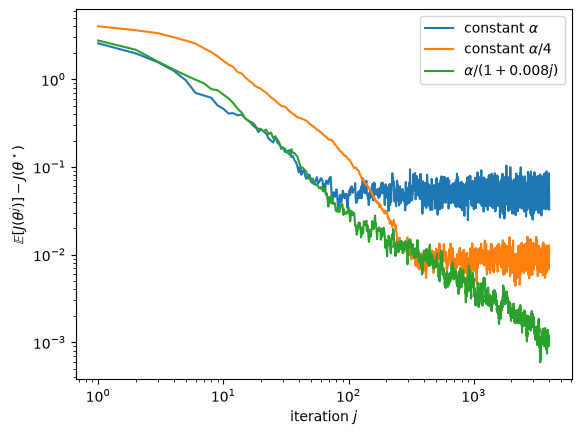

floor at alpha   : 5.29e-02
floor at alpha/4 : 9.38e-03
ratio            : 5.65   (Prop. 10.5.1 predicts 4)
decaying schedule at j = 4000: 1.12e-03

fixed-covariance exact floor: 3.87e-02, 8.84e-03, ratio 4.38
simulated fixed-noise floors: 3.87e-02, 8.82e-03, ratio 4.39
sigma^2 at distance 0.0: mean 0.560  (min 0.560, max 0.560)
sigma^2 at distance 0.5: mean 0.839  (min 0.577, max 1.211)
sigma^2 at distance 1.0: mean 1.675  (min 0.700, max 2.875)
sigma^2 at distance 2.0: mean 5.017  (min 1.263, max 9.240)


<Figure size 640x480 with 0 Axes>

In [16]:
# Question 6: your code here
from functools import partial

key_data = jax.random.PRNGKey(4) 
n_data = 400
A = jnp.diag(jnp.array([1.0, 0.38]))
theta_gen = jnp.array([1.0, -0.8])
noise = 0.7

def sample(key):
    key_z, key_eps = jax.random.split(key)
    x = A @ jax.random.normal(key_z, shape=(2,))
    y = x @ theta_gen + noise * jax.random.normal(key_eps)
    return x, y

def generate_data(key, n):
    keys = jax.random.split(key, n)
    X, Y = jax.vmap(sample)(keys)
    return X, Y

X_data, y_data = generate_data(key_data, n_data)
H = X_data.T @ X_data / n_data
theta_star = jnp.linalg.solve(X_data.T @ X_data, X_data.T @ y_data)
alpha = 1.0 / (4 * jnp.linalg.eigvalsh(H)[-1])

# L2 loss and gradients
def loss_i(theta, x, y):
    return 0.5 * (x @ theta - y) ** 2
grad_i = jax.grad(loss_i)

def batch_grad(theta, key, B):
    idx = jax.random.randint(key, (B,), 0, n_data)
    return jnp.mean(jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data[idx], y_data[idx]), axis=0)

def gap(theta):
    e = theta - theta_star
    return 0.5 * e @ H @ e

def per_sample_grads(theta):
    return jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data, y_data)

def sigma2(theta):
    G = per_sample_grads(theta)
    return jnp.mean(jnp.sum((G - G.mean(axis=0)) ** 2, axis=1))

@partial(jax.jit, static_argnames="B")
def sgd_gaps(key, theta0, alphas, B):
    def step(theta, inputs):
        k, a = inputs
        theta = theta - a * batch_grad(theta, k, B)
        return theta, gap(theta)
    _, gaps = jax.lax.scan(step, theta0, (jax.random.split(key, alphas.shape[0]), alphas))
    return jnp.concatenate([gap(theta0)[None], gaps])

def mean_sgd_gaps(key, theta0, alphas, B, runs):
    return jax.vmap(lambda k: sgd_gaps(k, theta0, alphas, B))(jax.random.split(key, runs)).mean(axis=0)

# Step-size schedules
key = jax.random.PRNGKey(0)
T, runs = 4000, 40
theta0 = jnp.array([-1.6, 2.2])
j = jnp.arange(T)

schedules = {
    "alpha":   (jnp.full(T, alpha),       r"constant $\alpha$"),
    "alpha/4": (jnp.full(T, alpha / 4),   r"constant $\alpha/4$"),
    "decay":   (alpha / (1 + 0.008 * j),  r"$\alpha/(1+0.008j)$"),
}
curves = {name: mean_sgd_gaps(jax.random.fold_in(key, i), theta0, a, B=1, runs=runs)
          for i, (name, (a, _)) in enumerate(schedules.items())}

for name, c in curves.items():
    plt.loglog(jnp.arange(1, T + 1), c[1:], label=schedules[name][1])
plt.xlabel("iteration $j$"); plt.ylabel(r"$\mathbb{E}[J(\theta^j)]-J(\theta^\star)$"); plt.legend()
plt.show()

plt.savefig("HW4Problem6.jpg")

# floors: average the flat tail of the two constant-step curves
f1 = curves["alpha"][1000:].mean()
f4 = curves["alpha/4"][1000:].mean()
print(f"floor at alpha   : {f1:.2e}")
print(f"floor at alpha/4 : {f4:.2e}")
print(f"ratio            : {f1 / f4:.2f}   (Prop. 10.5.1 predicts 4)")
print(f"decaying schedule at j = 4000: {curves['decay'][-1]:.2e}")

eigs, V = jnp.linalg.eigh(H)
S = jnp.cov(per_sample_grads(theta_star).T, bias=True)   # gradient-noise covariance at theta*
s2k = jnp.diag(V.T @ S @ V)                              # s_k^2 along the eigenvectors of H
floor_exact = lambda a: a / 2 * jnp.sum(s2k / (2 - a * eigs))
print(f"\nfixed-covariance exact floor: {floor_exact(alpha):.2e}, {floor_exact(alpha / 4):.2e}, "
      f"ratio {floor_exact(alpha) / floor_exact(alpha / 4):.2f}")

# Evaluation
@partial(jax.jit, static_argnames=("T", "burn"))
def fixed_noise_floor(key, a, T=6000, burn=2000):
    def step(e, k):
        xi = jax.random.multivariate_normal(k, jnp.zeros(2), S)
        e = e - a * (H @ e + xi)
        return e, 0.5 * e @ H @ e
    _, gaps = jax.lax.scan(step, theta0 - theta_star, jax.random.split(key, T))
    return gaps[burn:].mean()

sim = lambda a, k: jax.vmap(lambda kk: fixed_noise_floor(kk, a))(jax.random.split(k, 400)).mean()
a1, a4 = sim(alpha, jax.random.fold_in(key, 10)), sim(alpha / 4, jax.random.fold_in(key, 11))
print(f"simulated fixed-noise floors: {a1:.2e}, {a4:.2e}, ratio {a1 / a4:.2f}")

angles = jnp.linspace(0, 2 * jnp.pi, 36, endpoint=False)
for r in [0.0, 0.5, 1.0, 2.0]:
    pts = theta_star + r * jnp.stack([jnp.cos(angles), jnp.sin(angles)], axis=1)
    vals = jax.vmap(sigma2)(pts)
    print(f"sigma^2 at distance {r}: mean {vals.mean():.3f}  (min {vals.min():.3f}, max {vals.max():.3f})")

---

## Question 7

*Notes, Chapter 10, Exercise 26.*

Reproduce Figure 10.4. Using (10.9), run Algorithm 6 at $|\mathcal{B}| = 1, 16$ and $256$ with constant $\alpha$, averaging over at least 30 runs, and give every batch size the *same budget of sample evaluations* rather than the same number of iterations. Plot the loss gap twice, against $j$ and against $j|\mathcal{B}|$. Confirm the floors near $4.4 \times 10^{-2}$, $2.0 \times 10^{-3}$ and $1.1 \times 10^{-4}$. Then locate the interior optimum in the second plot: at a budget of 4000 evaluations which batch size is ahead, and at 96,000? Explain the crossing.

|B| =   1: 131072 iterations, floor (mean of last half) = 5.28e-02
|B| =  16:   8192 iterations, floor (mean of last half) = 2.46e-03
|B| = 256:    512 iterations, floor (mean of last half) = 1.50e-04


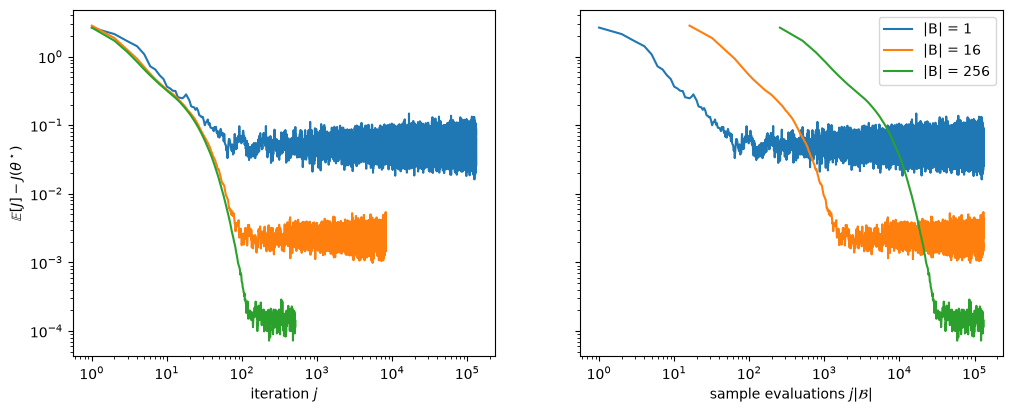

budget   4000: |B|=1: 7.15e-02, |B|=16: 1.59e-03, |B|=256: 2.15e-01   -> best |B| = 16
budget  96000: |B|=1: 6.03e-02, |B|=16: 1.89e-03, |B|=256: 1.37e-04   -> best |B| = 256
best batch size switches (budget, from, to): [(528, 1, 16), (541, 16, 1), (609, 1, 16), (18676, 16, 256), (19126, 256, 16), (19585, 16, 256), (20539, 256, 16), (21033, 16, 256)]


<Figure size 640x480 with 0 Axes>

In [17]:
# Question 7: your code here
from functools import partial

key_data = jax.random.PRNGKey(4)
n_data = 400
A = jnp.diag(jnp.array([1.0, 0.38]))
theta_gen = jnp.array([1.0, -0.8])
noise = 0.7

def sample(key):
    key_z, key_eps = jax.random.split(key)
    x = A @ jax.random.normal(key_z, shape=(2,))
    y = x @ theta_gen + noise * jax.random.normal(key_eps)
    return x, y

def generate_data(key, n):
    keys = jax.random.split(key, n)
    X, Y = jax.vmap(sample)(keys)
    return X, Y

X_data, y_data = generate_data(key_data, n_data)
H = X_data.T @ X_data / n_data
theta_star = jnp.linalg.solve(X_data.T @ X_data, X_data.T @ y_data) 
alpha = 1.0 / (4 * jnp.linalg.eigvalsh(H)[-1]) 

# L2 loss and gradients
def loss_i(theta, x, y):
    return 0.5 * (x @ theta - y) ** 2
grad_i = jax.grad(loss_i)

def batch_grad(theta, key, B):
    idx = jax.random.randint(key, (B,), 0, n_data)
    return jnp.mean(jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data[idx], y_data[idx]), axis=0)

def gap(theta):
    e = theta - theta_star
    return 0.5 * e @ H @ e

@partial(jax.jit, static_argnames="B")
def sgd_gaps(key, theta0, alphas, B):
    def step(theta, inputs):
        k, a = inputs
        theta = theta - a * batch_grad(theta, k, B)
        return theta, gap(theta)
    _, gaps = jax.lax.scan(step, theta0, (jax.random.split(key, alphas.shape[0]), alphas))
    return jnp.concatenate([gap(theta0)[None], gaps])

def mean_sgd_gaps(key, theta0, alphas, B, runs):
    return jax.vmap(lambda k: sgd_gaps(k, theta0, alphas, B))(jax.random.split(key, runs)).mean(axis=0)

# batch size = 1, 16, 256 at the same budget of sample evaluations
key = jax.random.PRNGKey(0)
runs, budget = 30, 2 ** 17
theta0 = jnp.array([-1.6, 2.2])

res = {}
for i, B in enumerate([1, 16, 256]):
    T = budget // B 
    res[B] = mean_sgd_gaps(jax.random.fold_in(key, i), theta0, jnp.full(T, alpha), B=B, runs=runs)
    print(f"|B| = {B:>3}: {T:>6} iterations, floor (mean of last half) = {res[B][T // 2:].mean():.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for B, g in res.items():
    j = jnp.arange(1, g.shape[0])
    ax[0].loglog(j, g[1:], label=f"|B| = {B}")
    ax[1].loglog(j * B, g[1:], label=f"|B| = {B}")
ax[0].set_xlabel("iteration $j$"); ax[1].set_xlabel(r"sample evaluations $j|\mathcal{B}|$")
ax[0].set_ylabel(r"$\mathbb{E}[J]-J(\theta^\star)$"); ax[1].legend()
plt.show()
plt.savefig("HW4Problem7.jpg")

def at_budget(B, evals): 
    return res[B][evals // B]

for E in [4000, 96000]:
    vals = {B: float(at_budget(B, E)) for B in res}
    best = min(vals, key=vals.get)
    print(f"budget {E:>6}: " + ", ".join(f"|B|={B}: {v:.2e}" for B, v in vals.items()) + f"   -> best |B| = {best}")

# sweep budget
budgets = np.unique(np.logspace(1, np.log10(budget), 400).astype(int))
best = [min(res, key=lambda B: float(at_budget(B, e)) if e >= B else np.inf) for e in budgets]
switches = [(int(budgets[i]), best[i - 1], best[i]) for i in range(1, len(budgets)) if best[i] != best[i - 1]]
print("best batch size switches (budget, from, to):", switches)

---

## Question 8

*Notes, Chapter 10, Exercise 27.*

Reproduce Figure 10.5. Using (10.10), implement (10.4) and record the two effective steps $\alpha/(\sqrt{v_k^j} + \epsilon)$ at every iteration. Plot both against $j$ on log–log axes. Confirm that the flat coordinate is stepped between roughly 7 and 130 times further than the steep one, and that neither curve settles. Then answer: the curvature ratio is 392, so why does the step ratio never approach it?

*Hint:* $v_k$ tracks the gradient, and the gradient in coordinate $k$ is $\lambda_k$ times the error in that coordinate, not $\lambda_k$.

diag(H) = [0.95215214 0.00242252],  curvature ratio = 393,  kappa = 393
flat/steep step ratio for j >= 10: min 3.4, max 83.5, median 14.6


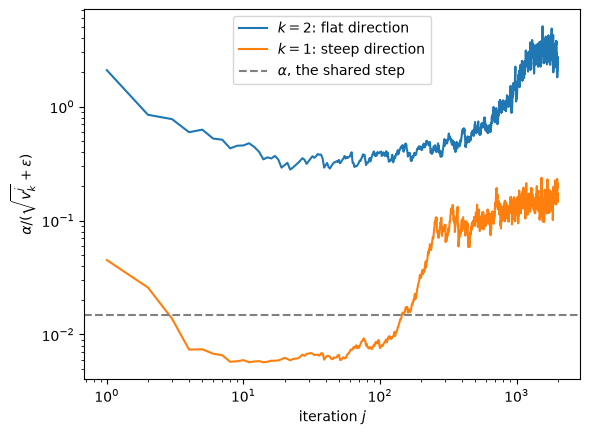

noise std of g_k at theta* (|B| = 16): s_1 = 0.0996, s_2 = 0.0052, s_1/s_2 = 19.1  (vs H_11/H_22 = 393)


<Figure size 640x480 with 0 Axes>

In [18]:
# Question 8: your code here
from functools import partial

key_data = jax.random.PRNGKey(19)
n_data = 500
A = jnp.diag(jnp.array([1.0, 0.05]))
theta_gen = jnp.array([1.0, -14.0])
noise = 0.4

def sample(key):
    key_z, key_eps = jax.random.split(key)
    x = A @ jax.random.normal(key_z, shape=(2,))
    y = x @ theta_gen + noise * jax.random.normal(key_eps)
    return x, y

def generate_data(key, n):
    keys = jax.random.split(key, n)
    X, Y = jax.vmap(sample)(keys)
    return X, Y

X_data, y_data = generate_data(key_data, n_data)
H = X_data.T @ X_data / n_data
theta_star = jnp.linalg.solve(X_data.T @ X_data, X_data.T @ y_data) 
eigs = jnp.linalg.eigvalsh(H)
print(f"diag(H) = {jnp.diag(H)},  curvature ratio = {H[0, 0] / H[1, 1]:.0f},  kappa = {eigs[-1] / eigs[0]:.0f}")

# Loss and gradients: J(theta) = (1/2n) sum_i (x_i^T theta - y_i)^2
def loss_i(theta, x, y):
    return 0.5 * (x @ theta - y) ** 2
grad_i = jax.grad(loss_i)

def batch_grad(theta, key, B):
    idx = jax.random.randint(key, (B,), 0, n_data)
    return jnp.mean(jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data[idx], y_data[idx]), axis=0)

def per_sample_grads(theta):                  # (n, 2): every grad l_i at theta
    return jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data, y_data)

# RMSProp, recording each coordinate's effective step
@partial(jax.jit, static_argnames=("T", "B"))
def run_rmsprop(key, theta0, alpha, T, B=16, rho=0.9, eps=1e-8):
    def step(state, k):
        theta, v = state
        g = batch_grad(theta, k, B)
        v = rho * v + (1 - rho) * g ** 2
        eff = alpha / (jnp.sqrt(v) + eps)
        theta = theta - eff * g
        return (theta, v), eff
    _, steps = jax.lax.scan(step, (theta0, jnp.zeros(2)), jax.random.split(key, T))
    return steps

key = jax.random.PRNGKey(0)                   # key for the run (separate from the data key)
theta0, T, alpha = jnp.array([-2.0, 2.0]), 2000, 0.0149     # alpha = tuned RMSProp value of Fig. 10.7
steps = run_rmsprop(key, theta0, alpha, T)
ratio = steps[:, 1] / steps[:, 0]
print(f"flat/steep step ratio for j >= 10: min {ratio[9:].min():.1f}, max {ratio[9:].max():.1f}, "
      f"median {jnp.median(ratio[9:]):.1f}")

j = jnp.arange(1, T + 1)
plt.loglog(j, steps[:, 1], label="$k=2$: flat direction")
plt.loglog(j, steps[:, 0], label="$k=1$: steep direction")
plt.axhline(alpha, ls="--", c="gray", label=r"$\alpha$, the shared step")
plt.xlabel("iteration $j$"); plt.ylabel(r"$\alpha/(\sqrt{v_k^j}+\epsilon)$"); plt.legend()
plt.show()
plt.savefig("HW4Problem8.jpg")

# Why the ratio never reaches 392: sqrt(v_k) ~ RMS of g_k = sqrt(H_kk^2 e_k^2 + s_k^2), so far from theta*
# the ratio tracks |H_11 e_1| / |H_22 e_2|, and near theta* it tracks the noise ratio s_1/s_2 -- never H_11/H_22.
S = jnp.cov(per_sample_grads(theta_star).T, bias=True) / 16     # batch-gradient noise at theta*, |B| = 16
print(f"noise std of g_k at theta* (|B| = 16): s_1 = {jnp.sqrt(S[0, 0]):.4f}, s_2 = {jnp.sqrt(S[1, 1]):.4f}, "
      f"s_1/s_2 = {jnp.sqrt(S[0, 0] / S[1, 1]):.1f}  (vs H_11/H_22 = {H[0, 0] / H[1, 1]:.0f})")

---

## Question 9

*Notes, Chapter 10, Exercise 28.*

Reproduce Figure 10.6. This one needs no simulation. Plot $(1 - \beta_1^j)/\sqrt{1 - \beta_2^j}$ against $j$ for $\beta_1 = 0.9$, $\beta_2 = 0.999$, and confirm the peak of 6.6 near $j = 12$. Show analytically why the curve rises before it falls, and find where the peak moves if $\beta_2$ is lowered to 0.99. Then run Adam on (10.10) with and without the correction and report the loss gap at $j = 50$ for each. You may be surprised which is ahead, and §10.7.2 explains why that is not an argument for dropping it.

beta2 = 0.999: f(1) = 3.16, peak 6.57 at j = 12, f(100) = 3.24, first j with f < 1.1: 1751
beta2 = 0.99: f(1) = 1.00, peak 2.13 at j = 13, f(100) = 1.26, first j with f < 1.1: 175


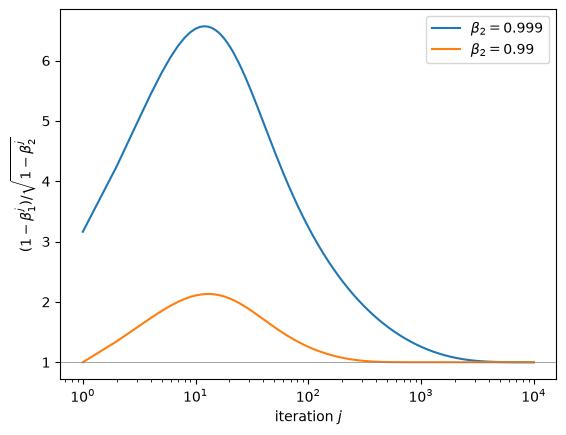

continuous peak, beta2 = 0.999: j* = 12.02
continuous peak, beta2 = 0.99: j* = 12.96
Adam with    correction: gap at j = 50: 1.572e+00,  j = 1500: 2.264e-04
Adam without correction: gap at j = 50: 1.166e-01,  j = 1500: 5.181e-04


<Figure size 640x480 with 0 Axes>

In [19]:
# Question 9: your code here
from functools import partial

# The bias-correction factor
def inflation(j, beta1=0.9, beta2=0.999):
    return (1 - beta1 ** j) / jnp.sqrt(1 - beta2 ** j)

j = jnp.arange(1, 10001)
for b2 in [0.999, 0.99]:
    f = inflation(j, beta2=b2)
    k = int(jnp.argmax(f))
    below = int(jnp.argmax((f < 1.1) & (j > j[k])))
    print(f"beta2 = {b2}: f(1) = {f[0]:.2f}, peak {f[k]:.2f} at j = {j[k]}, f(100) = {f[99]:.2f}, "
          f"first j with f < 1.1: {j[below]}")
    plt.semilogx(j, f, label=rf"$\beta_2={b2}$")
plt.axhline(1, c="gray", lw=0.5)
plt.xlabel("iteration $j$"); plt.ylabel(r"$(1-\beta_1^j)/\sqrt{1-\beta_2^j}$"); plt.legend()
plt.show()

plt.savefig("HW4Problem9.jpg")

# treat j as continuous and locate the peak of f on a fine grid
t = jnp.linspace(1.0, 100.0, 1_000_001)
for b2 in [0.999, 0.99]:
    print(f"continuous peak, beta2 = {b2}: j* = {t[jnp.argmax(inflation(t, beta2=b2))]:.2f}")

# Adam on Problem 10.10, with and without the bias correction
key_data = jax.random.PRNGKey(19)
n_data = 500
A = jnp.diag(jnp.array([1.0, 0.05]))
theta_gen = jnp.array([1.0, -14.0])
noise = 0.4

def sample(key):
    key_z, key_eps = jax.random.split(key)
    x = A @ jax.random.normal(key_z, shape=(2,))
    y = x @ theta_gen + noise * jax.random.normal(key_eps)
    return x, y

def generate_data(key, n):
    keys = jax.random.split(key, n)
    X, Y = jax.vmap(sample)(keys)
    return X, Y

X_data, y_data = generate_data(key_data, n_data)
H = X_data.T @ X_data / n_data
theta_star = jnp.linalg.solve(X_data.T @ X_data, X_data.T @ y_data)

# L2 loss and gradients
def loss_i(theta, x, y):
    return 0.5 * (x @ theta - y) ** 2
grad_i = jax.grad(loss_i)

def batch_grad(theta, key, B):
    idx = jax.random.randint(key, (B,), 0, n_data)
    return jnp.mean(jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X_data[idx], y_data[idx]), axis=0)

def gap(theta):
    e = theta - theta_star
    return 0.5 * e @ H @ e

@partial(jax.jit, static_argnames=("T", "B", "bias_correct"))
def adam_gaps(key, theta0, alpha, T, B=16, beta1=0.9, beta2=0.999, eps=1e-8, bias_correct=True):
    def step(state, inputs):
        theta, m, v = state
        k, j = inputs
        g = batch_grad(theta, k, B)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g ** 2
        m_hat, v_hat = (m / (1 - beta1 ** j), v / (1 - beta2 ** j)) if bias_correct else (m, v)
        theta = theta - alpha * m_hat / (jnp.sqrt(v_hat) + eps)
        return (theta, m, v), gap(theta)
    init = (theta0, jnp.zeros(2), jnp.zeros(2))
    _, gaps = jax.lax.scan(step, init, (jax.random.split(key, T), jnp.arange(1, T + 1)))   # j = 1..T
    return jnp.concatenate([gap(theta0)[None], gaps])

key = jax.random.PRNGKey(0)                   # key for the runs (separate from the data key)
theta0, alpha, runs = jnp.array([-2.0, 2.0]), 0.0304, 200
for i, bc in enumerate([True, False]):
    keys = jax.random.split(jax.random.fold_in(key, i), runs)
    g = jax.vmap(lambda k: adam_gaps(k, theta0, alpha, T=1500, bias_correct=bc))(keys).mean(axis=0)
    print(f"Adam {'with   ' if bc else 'without'} correction: gap at j = 50: {g[50]:.3e},  j = 1500: {g[1500]:.3e}")

---

## Question 10

*Notes, Chapter 10, Exercise 29.*

Reproduce Figure 10.7. Using (10.10), run SGD, momentum, RMSProp and Adam for 1500 iterations, averaged over 12 runs. Tune $\alpha$ separately for each by sweeping at least 30 values over four decades and keeping the best final loss. Do *not* share one $\alpha$, and explain in one sentence why sharing would invalidate the comparison. You should find tuned values near 0.76, 0.13, 0.015 and 0.030. Reproduce the four curves and confirm the ordering at $j = 1500$. Finally, rerun the whole comparison on the well conditioned (10.9) and report how the ranking changes.


[(10.10), kappa = 393] tuned alphas: sgd = 0.788, momentum = 0.08532, rmsprop = 0.01743, adam = 0.0329
[(10.10), kappa = 393] gap near j = 1500: adam = 2.05e-04, rmsprop = 4.42e-04, momentum = 3.21e-03, sgd = 4.56e-03   (best -> worst)
[(10.10), kappa = 393] SGD / best ratio: 22.3


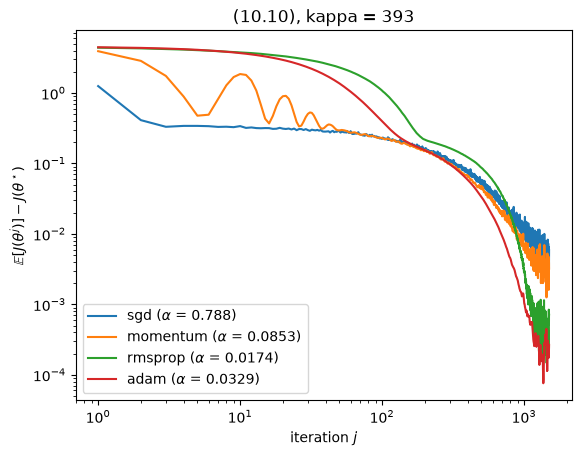


[(10.9), kappa = 6.8] tuned alphas: sgd = 0.02395, momentum = 0.002593, rmsprop = 0.003562, adam = 0.006723
[(10.9), kappa = 6.8] gap near j = 1500: adam = 7.69e-05, sgd = 2.04e-04, rmsprop = 2.25e-04, momentum = 2.26e-04   (best -> worst)
[(10.9), kappa = 6.8] SGD / best ratio: 2.6


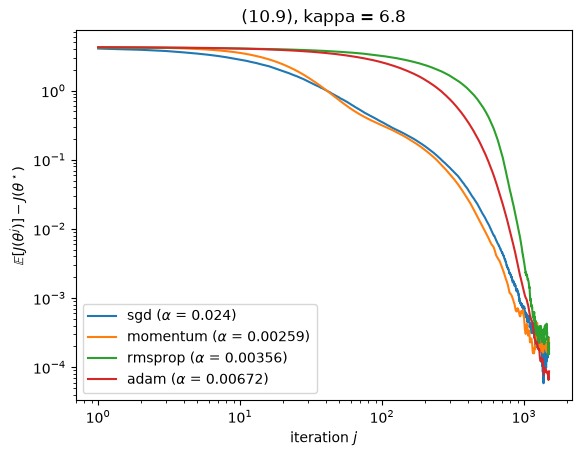

<Figure size 640x480 with 0 Axes>

In [20]:
# Question 10: your code here
from functools import partial

# Data generation
def generate_data(key, n, a2, theta_gen, noise):
    A = jnp.diag(jnp.array([1.0, a2]))
    def sample(key):
        key_z, key_eps = jax.random.split(key)
        x = A @ jax.random.normal(key_z, shape=(2,))
        y = x @ theta_gen + noise * jax.random.normal(key_eps)
        return x, y
    keys = jax.random.split(key, n)
    X, Y = jax.vmap(sample)(keys)
    return X, Y

X9, y9 = generate_data(jax.random.PRNGKey(4), 400, 0.38, jnp.array([1.0, -0.8]), 0.7)       # (10.9),  kappa = 6.8
X10, y10 = generate_data(jax.random.PRNGKey(19), 500, 0.05, jnp.array([1.0, -14.0]), 0.4)   # (10.10), kappa = 393

def loss_i(theta, x, y):                      # one sample's loss l_i
    return 0.5 * (x @ theta - y) ** 2
grad_i = jax.grad(loss_i)                     # one sample's gradient

# Optimizers
@partial(jax.jit, static_argnames=("method", "T", "B"))
def run_opt(X, y, key, theta0, alpha, method, T, B=16, beta=0.9, rho=0.9, beta1=0.9, beta2=0.999, eps=1e-8):
    n = X.shape[0]
    H = X.T @ X / n
    theta_star = jnp.linalg.solve(X.T @ X, X.T @ y)

    def gap(theta):
        e = theta - theta_star
        return 0.5 * e @ H @ e

    def batch_grad(theta, k):
        idx = jax.random.randint(k, (B,), 0, n)
        return jnp.mean(jax.vmap(grad_i, in_axes=(None, 0, 0))(theta, X[idx], y[idx]), axis=0)

    def step(state, inputs):
        theta, m, v = state
        k, j = inputs
        g = batch_grad(theta, k)
        if method == "sgd":                                    # Algorithm 6
            theta = theta - alpha * g
        elif method == "momentum":                             # Def. 4.5.1, stochastic gradient
            m = beta * m - alpha * g
            theta = theta + m
        elif method == "rmsprop":                              # (10.4)
            v = rho * v + (1 - rho) * g ** 2
            theta = theta - alpha * g / (jnp.sqrt(v) + eps)
        elif method == "adam":                                 # (10.6)-(10.7)
            m = beta1 * m + (1 - beta1) * g
            v = beta2 * v + (1 - beta2) * g ** 2
            theta = theta - alpha * (m / (1 - beta1 ** j)) / (jnp.sqrt(v / (1 - beta2 ** j)) + eps)
        return (theta, m, v), gap(theta)

    init = (theta0, jnp.zeros(2), jnp.zeros(2))
    _, gaps = jax.lax.scan(step, init, (jax.random.split(key, T), jnp.arange(1, T + 1)))   # j = 1..T
    return jnp.concatenate([gap(theta0)[None], gaps])

key = jax.random.PRNGKey(0)
methods = ["sgd", "momentum", "rmsprop", "adam"]
alphas = jnp.logspace(-3, 1, 30)
T, runs = 1500, 12

def compare(X, y, theta0, tag):
    best, curves = {}, {}
    for i, method in enumerate(methods):
        keys = jax.random.split(jax.random.fold_in(key, i), runs)
        g = jax.vmap(lambda a: jax.vmap(lambda k: run_opt(X, y, k, theta0, a, method, T))(keys))(alphas)
        final = g[:, :, -50:].mean(axis=(1, 2))
        final = jnp.where(jnp.isfinite(final), final, jnp.inf)
        k = int(jnp.argmin(final))
        best[method] = float(alphas[k])
        curves[method] = g[k].mean(axis=0)
    print(f"\n[{tag}] tuned alphas: " + ", ".join(f"{m} = {best[m]:.4g}" for m in methods))
    end = {m: float(curves[m][-50:].mean()) for m in methods}
    order = sorted(methods, key=end.get)
    print(f"[{tag}] gap near j = {T}: " + ", ".join(f"{m} = {end[m]:.2e}" for m in order) + "   (best -> worst)")
    print(f"[{tag}] SGD / best ratio: {end['sgd'] / end[order[0]]:.1f}")

    plt.figure()
    for m in methods:
        plt.loglog(jnp.arange(1, T + 1), curves[m][1:], label=rf"{m} ($\alpha$ = {best[m]:.3g})")
    plt.xlabel("iteration $j$"); plt.ylabel(r"$\mathbb{E}[J(\theta^j)]-J(\theta^\star)$"); plt.title(tag); plt.legend()
    plt.show()
    return best, curves

best10, curves10 = compare(X10, y10, jnp.array([-2.0, 2.0]), "(10.10), kappa = 393")
best9, curves9 = compare(X9, y9, jnp.array([-1.6, 2.2]), "(10.9), kappa = 6.8")

plt.savefig("HW4Problem10.jpg")

---

## Question 11

*Notes, Chapter 11, Exercise 15.*

Figure 11.5 shows a smooth target achieving slope $-2$ where the theorem guarantees only $-1$. Prove the sharper bound $|v - g| \le \frac{1}{8}h^2 \max|v''|$ for $v \in C^2$, and explain why Theorem 11.4.1 does not contradict it.

---

## Question 12

*Notes, Chapter 11, Exercise 18.*

Reproduce Figure 11.5. For a smooth target and for $v(x) = |x - c|$ with $c$ drawn at random, build the interpolant for $N = 2, 4, \dots, 256$, measure the maximum error, and fit the slope on log–log axes. Average the kink case over 60 values of $c$ and explain why a single $c$ gives an erratic curve.

smooth target       : slope -1.82
kink, mean of 60 c  : slope -0.92
kink, single c = 0.6282: slope -0.94, errors [0.06801 0.04849 0.05028 0.02561 0.0119  0.00424 0.00062 0.00193]
kink, single c = 0.1438: slope -1.11, errors [0.16352 0.08084 0.04612 0.02904 0.01153 0.00696 0.00384 0.00037]
kink, single c = 0.8984: slope -1.04, errors [0.14126 0.09997 0.0174  0.02334 0.01384 0.00736 0.00147 0.00076]
check: formula 0.025605 vs measured 0.025605


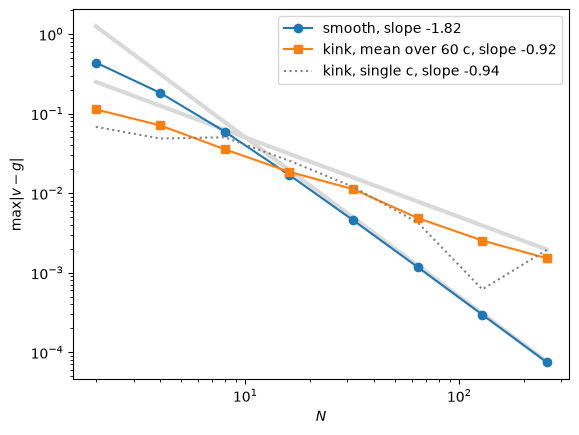

<Figure size 640x480 with 0 Axes>

In [21]:
# Question 12: your code here

key = jax.random.PRNGKey(0)
a, b = 0.0, 1.0
Ns = [2 ** p for p in range(1, 9)]
x_fine = jnp.linspace(a, b, 200001)

def interp_max_err(v, N, extra=jnp.zeros(0)):
    """Max error of the piecewise-linear interpolant (Def. 11.3.2) on N + 2 uniform nodes."""
    nodes = jnp.linspace(a, b, N + 2)
    xe = jnp.sort(jnp.concatenate([x_fine, extra]))
    g = jnp.interp(xe, nodes, v(nodes))
    return jnp.max(jnp.abs(v(xe) - g))

def fit_slope(errs):
    return jnp.polyfit(jnp.log10(jnp.array(Ns, float)), jnp.log10(errs), 1)[0]

# smooth (C^2) target
smooth = lambda x: jnp.sin(2 * jnp.pi * x)
err_s = jnp.array([interp_max_err(smooth, N) for N in Ns])

# kinked target averaged over 60 random kink positions
cs = jax.random.uniform(key, (60,), minval=a, maxval=b)
def kink_errs(c):
    return jnp.array([interp_max_err(lambda x: jnp.abs(x - c), N, c[None]) for N in Ns])
err_k_all = jax.vmap(kink_errs)(cs)
err_k = err_k_all.mean(axis=0)

print(f"smooth target       : slope {fit_slope(err_s):.2f}")
print(f"kink, mean of 60 c  : slope {fit_slope(err_k):.2f}")
for i in range(3):
    print(f"kink, single c = {cs[i]:.4f}: slope {fit_slope(err_k_all[i]):.2f}, errors {jnp.round(err_k_all[i], 5)}")

c, N = cs[0], 16
nodes = jnp.linspace(a, b, N + 2); h = nodes[1] - nodes[0]; i = jnp.searchsorted(nodes, c)
print(f"check: formula {2 * (c - nodes[i - 1]) * (nodes[i] - c) / h:.6f} vs measured "
      f"{interp_max_err(lambda x: jnp.abs(x - c), N, c[None]):.6f}")

Ns_arr = jnp.array(Ns, float)
plt.loglog(Ns_arr, err_s, "o-", label=f"smooth, slope {fit_slope(err_s):.2f}")
plt.loglog(Ns_arr, err_k, "s-", label=f"kink, mean over 60 c, slope {fit_slope(err_k):.2f}")
plt.loglog(Ns_arr, err_k_all[0], ":", c="gray", label=f"kink, single c, slope {fit_slope(err_k_all[0]):.2f}")
plt.loglog(Ns_arr, 0.5 / Ns_arr, c="0.85", lw=3, zorder=0)
plt.loglog(Ns_arr, 5 / Ns_arr ** 2, c="0.85", lw=3, zorder=0)
plt.xlabel("$N$"); plt.ylabel(r"$\max|v-g|$"); plt.legend()
plt.show()

plt.savefig("HW4Problem12.jpg")